In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.optimize import curve_fit
import scipy.stats as stats
from matplotlib.colors import ListedColormap

plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9
})

In [2]:
def read_all_weights(stimulation = "1000_5_0.5_0.1"):
  print(f"Processing stimulation {stimulation}")
  cell_ids = np.arange(0, 20)
  cell_weights = {}
  time = []
  for cell_id in cell_ids:
    cell_weights[cell_id] = pd.read_csv(f"output/temporal-interference-1/{cell_id}/in-vivo/{stimulation}/synapse_weights.csv", index_col = 0)
    time.append(cell_weights[cell_id].Time)

  time = np.concatenate(time)
  time = np.unique(time)
  time = np.sort(time)
  print(f"Number of time points: {len(time)}")

  synapses = [ f"Synapse{id}" for id in range(0, 10) ]
  for cell_id in cell_ids:
    cell_weights[cell_id] = (
      cell_weights[cell_id].set_index("Time")[synapses]
      .reindex(time, method = "ffill")
      .to_numpy()
      .T
    )

  weights = np.concatenate([
    cell_weights[cell_id]
    for cell_id in cell_ids
  ], axis = 0)

  weights = pd.DataFrame(
    weights.T,
    index = time
  )

  return weights

In [3]:
colors = {
  "No tTIS": "#0D0887",
  "50% tTIS": "#E16462",
  "90% tTIS": "#B12A90"
}

stimulations = list(colors.keys())

weights = {
  "No tTIS": read_all_weights("noTI_0.1"),
  "50% tTIS": read_all_weights("1000_5_0.5_0.1"),
  "90% tTIS": read_all_weights("1000_5_0.9_0.1")
}

Processing stimulation noTI_0.1
Number of time points: 6778
Processing stimulation 1000_5_0.5_0.1
Number of time points: 8677
Processing stimulation 1000_5_0.9_0.1
Number of time points: 12166


In [4]:
def format_ax(ax, grid = True):
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)

  for spine in ax.spines.values():
    spine.set_color("gray")

  ax.tick_params(axis="both", colors="#1a1a1a")

  if grid:
    ax.grid(alpha = 0.5, zorder = 0)

In [5]:
def expand_time(weights, time_step = 0.025, sample_time_step = 0.5):
  print(f"Original data dimensions: {weights.shape}")
  time = weights.index
  weights_to_update = weights.copy()
  max_time = time.max()

  time = (time / time_step).round() * time_step
  weights_to_update.index = time

  new_time = np.arange(0, max_time + time_step, time_step)
  new_weights = pd.DataFrame(weights_to_update).set_index(time).reindex(new_time, method = "ffill")
  print(f"Expanded data dimensions: {new_weights.shape}")

  # sample every sample_time_step
  sampled_time = np.arange(0, max_time, sample_time_step)
  new_weights = new_weights.loc[sampled_time]
  print(f"Resampled data dimensions: {new_weights.shape}")

  return new_weights

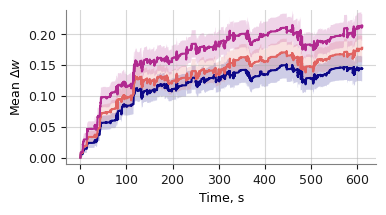

In [6]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (4, 2))

ax = axs
for stimulation in stimulations:
  w = np.abs(weights[stimulation] - 0.1)
  time = w.index / 1000
  mean = w.mean(axis = 1)
  error = w.std(axis = 1) / np.sqrt(w.shape[1])

  ax.plot(time, mean, label = stimulation, color = colors[stimulation])

  ax.fill_between(
    time,
    mean - error,
    mean + error,
    alpha = 0.2,
    color = colors[stimulation],
    edgecolor = None
  )

ax.set_xlabel("Time, s")
ax.set_ylabel(rf"Mean $\Delta w$")
ax.grid(alpha = 0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylim(-0.01, 0.24)

# ax.legend(
#   bbox_to_anchor = (1.02, 0.5),
#   loc = "center left",
#   frameon = False
# )

format_ax(ax)

plt.show()

In [7]:
expanded_weights = {
  "No tTIS": expand_time(weights = weights["No tTIS"]),
  "50% tTIS": expand_time(weights = weights["50% tTIS"]),
  "90% tTIS": expand_time(weights = weights["90% tTIS"])
}

mean_weights = {}
for stimulation in weights.keys():
  mean = expanded_weights[stimulation].mean(axis = 1)
  time = expanded_weights[stimulation].index

  mean_weights[stimulation] = pd.DataFrame({
    "Time": time,
    "Mean": mean
  })

Original data dimensions: (6778, 200)


Expanded data dimensions: (24445131, 200)
Resampled data dimensions: (1222257, 200)
Original data dimensions: (8677, 200)
Expanded data dimensions: (24445133, 200)
Resampled data dimensions: (1222257, 200)
Original data dimensions: (12166, 200)
Expanded data dimensions: (24445126, 200)
Resampled data dimensions: (1222257, 200)


In [8]:
def rising_double_exp(t, a1, tau1, a2, tau2):
  w0 = 0.1 # known from experimental setup
  t0 = 0 # starting time is zero

  return w0 + a1 * (1 - np.exp(-(t - t0) / tau1)) + a2 * (1 - np.exp(-(t - t0) / tau2))

def rising_exp(t, a1, tau1):
  w0 = 0.1 # known from experimental setup
  t0 = 0 # starting time is zero

  return w0 + a1 * (1 - np.exp(-(t - t0) / tau1))

def fit_double_exponential(weights, time):
  w = np.array(weights).mean(axis = 0)
  t = np.array(time)

  popt, _ = curve_fit(
    f = rising_double_exp,
    xdata = t,
    ydata = w,
    p0 = [0.1, 1.0, 0.1, 2.0],
    bounds = ([0, 1e-6, 0, 1e-6], [100, 600, 100, 600])
  )
  a1, tau1, a2, tau2 = popt

  # Swap for consistency: tau1 always lower than tau2
  a1, tau1, a2, tau2 = (a2, tau2, a1, tau1) if tau1 > tau2 else (a1, tau1, a2, tau2)

  return rising_double_exp(t, a1, tau1, a2, tau2), {
    "a1": a1, "tau1": tau1, "a2": a2, "tau2": tau2
  }

def fit_exponential(weights, time):
  t = np.array(time)
  
  amp_guess = weights.max() - weights.min()

  popt, _ = curve_fit(
    f = rising_exp,
    xdata = t,
    ydata = weights,
    p0 = [amp_guess, 1.0],
    bounds = ([0, 1e-6], [100, 600])
  )
  a1, tau1 = popt

  return rising_exp(t, a1, tau1), {
    "a1": a1, "tau1": tau1
  }


fit = []

for stimulation in mean_weights.keys():
  print(stimulation)
  means = mean_weights[stimulation]
  _, results = fit_exponential(means.Mean, means.Time / 1000)
  fit.append(pd.DataFrame({
    "Stimulation": [stimulation],
    "A": round(results["a1"], 2),
    "Tau": round(results["tau1"], 2)
  }))
  
  print(results)

fit = pd.concat(fit, ignore_index = True)
fit

No tTIS
{'a1': 0.1385932108635459, 'tau1': 107.56563479283945}
50% tTIS
{'a1': 0.15537452892727455, 'tau1': 103.49713852068685}
90% tTIS
{'a1': 0.18874393173861295, 'tau1': 94.10873594423965}


,Stimulation,A,Tau
0,No tTIS,0.14,107.57
1,50% tTIS,0.16,103.50
2,90% tTIS,0.19,94.11


In [9]:
def categorize(w, atol = 1e-4):
  if w > 0.1 + atol: return "LTP"
  if w < 0.1 - atol: return "LTD"
  return "Stable"

order = ["LTP", "Stable", "LTD"]

In [10]:
weight_categories = []

for stimulation in expanded_weights.keys():
  w = expanded_weights[stimulation]
  
  max_time = w.index[-1] / 1000
  time_select = np.where(w.index >= (max_time - 0.5) * 1000)[0]
  final_weights = w.iloc[ time_select ].mean(axis = 0).tolist()

  categories = pd.DataFrame({
    "Stimulation": stimulation,
    "Weight": final_weights,
    "SynapseID": w.columns,
    "Category": [ categorize(w_) for w_ in final_weights ]
  })

  categories["Category"] = pd.Categorical(categories["Category"], categories = order, ordered = True)

  weight_categories.append(categories)

weight_categories = pd.concat(weight_categories, ignore_index = True)
weight_categories

,Stimulation,Weight,SynapseID,Category
0,No tTIS,0.755637,0,LTP
1,No tTIS,0.794472,1,LTP
2,No tTIS,0.099886,2,LTD
3,No tTIS,0.100000,3,Stable
4,No tTIS,0.929080,4,LTP
...,...,...,...,...
595,90% tTIS,0.095345,195,LTD
596,90% tTIS,0.100000,196,Stable
597,90% tTIS,0.082406,197,LTD
598,90% tTIS,0.235758,198,LTP


In [11]:
def p_to_stars(p):
  if p < 1e-4:
    return "****"
  elif p < 1e-3:
    return "***"
  elif p < 1e-2:
    return "**"
  elif p < 0.05:
    return "*"
  else:
    return "ns"

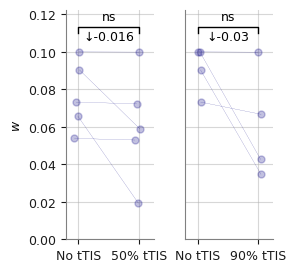

In [12]:
fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (3, 2.8), sharey = True)

type = "LTD"

for ax, stimulation in zip(axs, ["50% tTIS", "90% tTIS"]):
  # Intersection
  synapse_ids = list(
    set(weight_categories[(weight_categories.Category == type) & (weight_categories.Stimulation == stimulation)].SynapseID) &
    set(weight_categories[(weight_categories.Category == type) & (weight_categories.Stimulation == "No tTIS")].SynapseID)
  )

  w = weight_categories[ weight_categories["SynapseID"].isin(synapse_ids) ]

  y1 = w[ w.Stimulation == "No tTIS" ].set_index("SynapseID").loc[synapse_ids].reset_index()
  y2 = w[ w.Stimulation == stimulation ].set_index("SynapseID").loc[synapse_ids].reset_index()

  assert (y1.SynapseID.values == y2.SynapseID.values).all()

  y1 = y1.Weight.values
  y2 = y2.Weight.values

  x = [0, 1]
  jitter = 0.05
  x1 = np.random.normal(loc = 0, scale = jitter, size = len(y1))
  x2 = x1 + 1

  has_label_higher = False
  has_label_lower = False
  for i in range(len(y1)):
    if y1[i] > y2[i]:
      color = colors["No tTIS"]
      label = "" if has_label_higher else rf"$w_{{\text{{tTIS}}}} < w_{{\text{{no tTIS}}}}$"
      has_label_higher = True
    else:
      color = colors["50% tTIS"]
      label = "" if has_label_lower else rf"$w_{{\text{{tTIS}}}} > w_{{\text{{no tTIS}}}}$"
      has_label_lower = True

    points_x = [ x1[i], x2[i] ]
    points_y = [ y1[i], y2[i] ]

    ax.plot(points_x, points_y, color = color, linewidth = 0.1, alpha = 1, zorder = 5)

    ax.scatter(points_x, points_y, color = color, s = 25, alpha = 0.25, zorder = 10, label = label)
    
  ax.set_xticks(x, ["No tTIS", stimulation])
  ax.set_ylabel(rf"$w$")
  ax.set_xlim(-0.2, 1.25)

  if type == "LTD":
    ax.set_ylim(0, 0.122)

  format_ax(ax)

  # Add test statistics
  stat, p = stats.wilcoxon(y1, y2)
  stars = p_to_stars(p)

  y_max = max(np.max(y1), np.max(y2))
  
  y = y_max * 1.1

  ax.plot([0, 0, 1, 1], [y, y * 1.03, y * 1.03, y], color="black", linewidth=1)
  ax.text(0.5, y * 1.05, stars, ha="center", va="bottom", fontsize=9)

  symbol = "↑" if type == "LTP" else "↓"
  diff = np.mean(y2 - y1)
  text = f"{symbol}{diff:.2}"

  ax.text(0.5, y * 0.95, text, ha="center", va="bottom", fontsize=9)

axs[1].set_ylabel("")
axs[1].tick_params(left = False)

plt.tight_layout()
plt.show()

In [13]:
stimulation = "50% tTIS"
no_ti = weight_categories[ weight_categories.Stimulation == "No tTIS" ].Category.values
ti = weight_categories[ weight_categories.Stimulation == stimulation ].Category.values

transition = pd.crosstab(no_ti, ti)

transition

col_0,LTP,Stable,LTD
row_0,,,
LTP,50,0,0
Stable,9,115,16
LTD,4,1,5


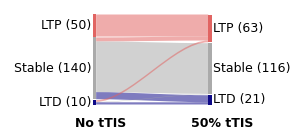

In [14]:
from sankeyflow import Sankey

color_map = {
    "LTP": f"{colors['50% tTIS']}",
    "LTD": f"{colors['No tTIS']}",
    "Stable": "#AAAAAA"
}

nodes = [
  [ (f" {cat}", transition.loc[cat].sum(), {"color": color_map[cat]}) for cat in transition.index ],
  [ (f"{cat}", transition[cat].sum(), {"color": color_map[cat]}) for cat in transition.columns ]
]

flows = []

for src in transition.index:
  for tgt in transition.columns:
    value = transition.loc[src, tgt]
    if value > 0:
      flows.append((
        f" {src}",
        f"{tgt}",
        value,
        {"color": f"{color_map[tgt]}88"}
      ))

plt.figure(figsize = (3, 1.5))
sankey = Sankey(
  nodes = nodes,
  flows = flows,
  node_opts = {
    "label_format": "{label} ({value:.0f})",
    "label_opts": {
      "fontsize": 9
    }
  }
)

sankey.draw()

ax = plt.gca()

for text in ax.texts:
  x, y = text.get_position()
  if x > 0.9:
    text.set_x(x + 0.05)
    text.set_ha("left")

ax.text(
  -0.15, -0.25,
  "No tTIS",
  fontweight = "semibold"
)

ax.text(
  1 - 0.15, -0.25,
  stimulation,
  fontweight = "semibold"
)

plt.tight_layout()
plt.show()

In [15]:
cell_ids = np.arange(0, 20)
rates = {
  "No tTIS": [],
  "50% tTIS": [],
  "90% tTIS": []
}

for cell_id in cell_ids:
  spikes = pd.read_csv(f"output/temporal-interference-1/{cell_id}/in-vivo/1000_5_0.5_0.1/spike_frequency.csv", index_col = 0)
  rate = (len(spikes) + 1 if len(spikes) >= 1 else 0) / (610)
  rates["50% tTIS"].append(rate)

  spikes = pd.read_csv(f"output/temporal-interference-1/{cell_id}/in-vivo/1000_5_0.9_0.1/spike_frequency.csv", index_col = 0)
  rate = (len(spikes) + 1 if len(spikes) >= 1 else 0) / (610)
  rates["90% tTIS"].append(rate)

  spikes = pd.read_csv(f"output/temporal-interference-1/{cell_id}/in-vivo/noTI_0.1/spike_frequency.csv", index_col = 0)
  rate = (len(spikes) + 1 if len(spikes) >= 1 else 0) / (610)
  rates["No tTIS"].append(rate)

rates = pd.DataFrame(rates)

mean = rates["No tTIS"].mean()
sd = rates["No tTIS"].std()
print(f"No tTIS: {mean:.2f} +- {sd:.2f}")

mean = rates["50% tTIS"].mean()
sd = rates["50% tTIS"].std()
print(f"50% tTIS: {mean:.2f} +- {sd:.2f}")

mean = rates["90% tTIS"].mean()
sd = rates["90% tTIS"].std()
print(f"90% tTIS: {mean:.2f} +- {sd:.2f}")

No tTIS: 0.00 +- 0.00
50% tTIS: 0.05 +- 0.07
90% tTIS: 0.27 +- 0.25


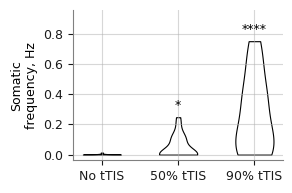

In [16]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (3, 2))
ax = axs

violin = ax.violinplot(
  rates,
  showmeans = False,
  showmedians = False,
  showextrema = False
)

for body in violin["bodies"]:
  body.set_facecolor("white")
  body.set_edgecolor("black")
  body.set_linewidth(0.8)
  body.set_alpha(1)

# ticks
ax.set_xticks(range(1, len(rates.columns) + 1))
ax.set_xticklabels(rates.columns)

ax.set_ylabel("Somatic\nfrequency, Hz")
ax.set_xlabel("")

format_ax(ax)

# stats vs No TI
ref_idx = "No tTIS"

y_max = rates.max().max()
y_offset = 0.05 * y_max

for stimulation in rates.columns:
  if stimulation == ref_idx:
    continue

  stat, p_val = stats.mannwhitneyu(rates[ref_idx], rates[stimulation], alternative="two-sided")
  stars = p_to_stars(p_val)

  x = np.where(rates.columns == stimulation)[0] + 1
  y = rates[stimulation].max() + y_offset

  ax.text(x, y, stars, ha="center", va="bottom")

ax.set_ylim(top=y_max + 5.5 * y_offset)

plt.tight_layout()
plt.show()

No tTIS
3
50% tTIS
3
90% tTIS
3


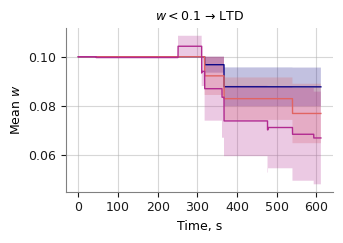

In [17]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (3.5, 2.5))

type = "LTD"

ax = axs
for stimulation in weights.keys():
  w = weights[stimulation]

  synapses = list(
    set(weight_categories[(weight_categories.Category == type) & (weight_categories.Stimulation == "90% tTIS")].SynapseID) &
    set(weight_categories[(weight_categories.Category == type) & (weight_categories.Stimulation == "50% tTIS")].SynapseID) &
    set(weight_categories[(weight_categories.Category == type) & (weight_categories.Stimulation == "No tTIS")].SynapseID)
  )
  w = w[synapses]

  print(stimulation)
  print(len(synapses))

  time = w.index / 1000
  mean = np.mean(w, axis = 1)
  error = w.std(axis = 1) / np.sqrt(w.shape[1])

  ax.plot(
    time,
    mean,
    color = colors[stimulation],
    linewidth = 1,
    zorder = 5
  )

  ax.fill_between(
    time,
    mean - error,
    mean + error,
    color = colors[stimulation],
    alpha = 0.25,
    edgecolor = None,
    zorder = 2
  )

ax.set_ylabel(rf"Mean $w$")
ax.set_xlabel("Time, s")

if type == "LTD":
  ax.set_title(rf"$w < 0.1$ → LTD")

if type == "LTP":
  ax.set_title(rf"$w > 0.1$ → LTP")

format_ax(ax)

# ax.set_ylim(0.055, 0.125)

plt.tight_layout()
plt.show()

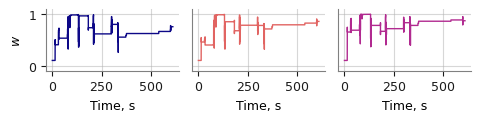

In [18]:
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (5, 1.3), sharey = True)

# ax = axs
for ax, stimulation in zip(axs, weights.keys()):
  w = weights[stimulation]

  synapses = weight_categories[ (weight_categories.Stimulation == stimulation) & (weight_categories.Category == "LTP") ].SynapseID.values[0]
  w = w[synapses]

  time = w.index / 1000

  ax.plot(
    time,
    w,
    color = colors[stimulation],
    linewidth = 1,
    zorder = 5
  )

  ax.set_ylabel(rf"$w$")
  ax.set_xlabel("Time, s")

  # ax.set_title(stimulation)

  ax.set_ylim(-0.1, 1.1)

  format_ax(ax)

for ax in axs[1:3]:
  ax.tick_params(left = None, labelleft = None)
  ax.set_ylabel("")

plt.tight_layout()
plt.show()

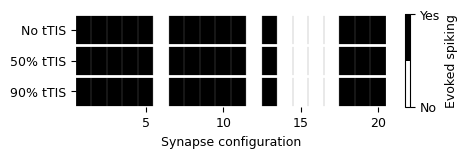

In [41]:
def read_all_frequencies(stimulation):
  cell_ids = np.arange(0, 20)
  frequencies = []
  for cell_id in cell_ids:
    filename = f"output/temporal-interference-1/{cell_id}/post-stimulation/in-vivo/{stimulation}/spike_times.csv"

    spikes = pd.read_csv(filename, index_col = 0)
    frequency = len(spikes) # / (spikes.Time.max() - spikes.Time.min())
    # frequency = 0 if np.isnan(frequency) else frequency
    frequencies.append(frequency)

  return frequencies

frequencies = {
  "No tTIS": read_all_frequencies("noTI_0.1"),
  "50% tTIS": read_all_frequencies("1000_5_0.5_0.1"),
  "90% tTIS": read_all_frequencies("1000_5_0.9_0.1")
}


matrix = np.array(list(frequencies.values())).astype(bool)
cmap = ListedColormap(["white", "black"])

fig, ax = plt.subplots(figsize = (5, 1.2))

im = ax.imshow(matrix, aspect="auto", cmap=cmap, vmin=0, vmax=1)

# integer column indices
ax.set_xticks(np.arange(4, matrix.shape[1], 5))
ax.set_xticklabels(np.arange(0, matrix.shape[1], 5) + 5)

# row labels
ax.set_yticks(np.arange(matrix.shape[0]))
ax.set_yticklabels(list(frequencies.keys()))

# create spacing using gridlines
ax.set_xticks(np.arange(-.5, matrix.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, matrix.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", linestyle="-", linewidth=2, axis = "y")
ax.grid(which="minor", color="gray", linestyle="-", linewidth=0.25, axis = "x")
ax.tick_params(which="minor", bottom=False, left=False)

# plt.colorbar(im, ticks=[0,1], label="Evoked spiking")
cbar = plt.colorbar(im, ticks=[0, 1])
cbar.ax.set_yticklabels(["No", "Yes"])
cbar.set_label("Evoked spiking")

for spine in ax.spines.values():
  spine.set_visible(False)

plt.xlabel("Synapse configuration")
plt.ylabel("")
plt.show()


In [20]:
cell_id = 0

filename = f"output/temporal-interference-1/{cell_id}/in-vivo/noTI_0.1/voltage.csv"
voltage = pd.read_csv(filename, index_col = 0)

filename = f"output/temporal-interference-1/{cell_id}/in-vivo/1000_5_0.5_0.1/voltage.csv"
voltage_50 = pd.read_csv(filename, index_col = 0)

filename = f"output/temporal-interference-1/{cell_id}/in-vivo/1000_5_0.9_0.1/voltage.csv"
voltage_90 = pd.read_csv(filename, index_col = 0)

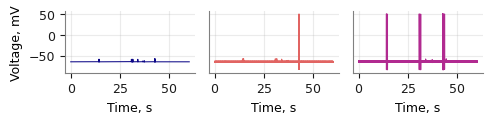

In [21]:
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (5, 1.3), sharey = True)

axs[0].plot(voltage.Time / 1000, voltage.Voltage, linewidth = 0.75, color = colors["No tTIS"])
axs[1].plot(voltage_50.Time / 1000, voltage_50.Voltage, linewidth = 0.75, color = colors["50% tTIS"])
axs[2].plot(voltage_90.Time / 1000, voltage_90.Voltage, linewidth = 0.75, color = colors["90% tTIS"])

for ax in axs:
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)
  ax.grid(alpha = 0.25)

  for spine in ax.spines.values():
    spine.set_color("gray")

  ax.tick_params(axis="both", colors="#1a1a1a")

  ax.set_xlabel("Time, s")

axs[1].tick_params(left = False, labelleft = False)
axs[2].tick_params(left = False, labelleft = False)

axs[0].spines["left"].set_visible(True)
axs[0].set_ylabel("Voltage, mV")

plt.tight_layout()
plt.show()

In [22]:
def read_stimuli(cell_id):
  stimuli = pd.read_csv(
    f"output/temporal-interference-1/{cell_id}/in-vivo/noTI_0.1/synapse_stimuli.csv",
    header = None
  )
  stimuli = stimuli.fillna('').values.tolist()
  stimuli = [[x for x in row if x != ""] for row in stimuli]

  return stimuli


synapse_number = 0
cell_id = 0

synapse_id = f"Synapse{synapse_number}_cell{cell_id}"
stimuli = read_stimuli(cell_id)[synapse_number]

In [23]:
def plot_stimuli(ax, stimuli):
  synapse_stimuli = np.array(stimuli) / 1000
  ax.eventplot(synapse_stimuli, linelengths = 0.75, colors = "black", linewidths = 0.5)

  ax.set_ylim(0.5, 1.5)
  # ax.set_xlim(0, 10)
  ax.tick_params(left = False, labelleft = False, bottom = False, labelbottom = False)

  for spine in ax.spines:
    ax.spines[spine].set_visible(False)

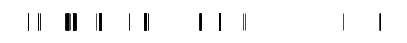

In [24]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (5, 0.3))

plot_stimuli(ax = axs, stimuli = stimuli)


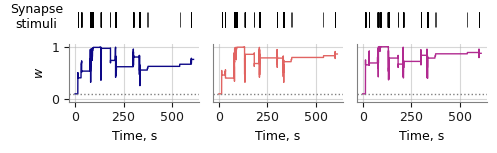

In [25]:
synapse_id = 0

fig, axs = plt.subplots(nrows = 2, ncols = 3, figsize = (5, 1.6), sharex = True, height_ratios = [0.25, 0.75])

for ax, stimulation in zip(axs[1], weights.keys()):    
  w = weights[stimulation][synapse_id]

  ax.plot(
    w.index / 1000,
    w.values,
    color = colors[stimulation],
    linewidth = 1
  )

  format_ax(ax)
  ax.set_ylim(-0.05, 1.05)
  ax.set_ylabel(rf"$w$")
  ax.set_xlabel("Time, s")

  ax.axhline(y = 0.1, linestyle = ":", linewidth = 1, color = "gray")

for ax in axs[1][1:3]:
  ax.set_ylabel("")
  ax.tick_params(left = False, labelleft = False)

for ax in axs[0]:
  plot_stimuli(ax, stimuli)

axs[0][0].set_ylabel("Synapse\nstimuli", rotation = 0)
axs[0][0].yaxis.set_label_coords(-0.25, -0.1)

plt.tight_layout()
plt.show()

In [35]:
mean_weights = {}
for stimulation in weights.keys():
  mean = np.abs(weights[stimulation] - 0.1).mean(axis = 1)
  time = weights[stimulation].index / 1000

  mean_weights[stimulation] = pd.DataFrame({
    "Time": time,
    "Mean": mean
  })

from scipy.optimize import curve_fit

def rising_double_exp(t, a1, tau1, a2, tau2):
  w0 = 0
  t0 = 0 # starting time is zero

  return w0 + a1 * (1 - np.exp(-(t - t0) / tau1)) + a2 * (1 - np.exp(-(t - t0) / tau2))

def rising_exp(t, a1, tau1):
  w0 = 0
  t0 = 0 # starting time is zero

  return w0 + a1 * (1 - np.exp(-(t - t0) / tau1))

def fit_double_exponential(weights, time):
  t = np.array(time)

  popt, _ = curve_fit(
    f = rising_double_exp,
    xdata = t,
    ydata = weights,
    p0 = [0.1, 1.0, 0.1, 2.0],
    bounds = ([0, 1e-6, 0, 1e-6], [100, 600, 100, 600])
  )
  a1, tau1, a2, tau2 = popt

  # Swap for consistency: tau1 always lower than tau2
  a1, tau1, a2, tau2 = (a2, tau2, a1, tau1) if tau1 > tau2 else (a1, tau1, a2, tau2)

  return rising_double_exp(t, a1, tau1, a2, tau2), {
    "a1": a1, "tau1": tau1, "a2": a2, "tau2": tau2
  }

def fit_exponential(weights, time):
  t = np.array(time)
  
  amp_guess = weights.max() - weights.min()

  popt, _ = curve_fit(
    f = rising_exp,
    xdata = t,
    ydata = weights,
    p0 = [amp_guess, 1.0],
    bounds = ([0, 1e-6], [100, 600])
  )
  a1, tau1 = popt

  return rising_exp(t, a1, tau1), {
    "a1": a1, "tau1": tau1
  }



fit = []

for stimulation in mean_weights.keys():
  print(stimulation)
  means = mean_weights[stimulation]
  _, results = fit_exponential(means.Mean, means.Time)
  fit.append(pd.DataFrame({
    "Stimulation": [stimulation],
    "A": round(results["a1"], 2),
    "Tau": round(results["tau1"], 2)#,
    # "A2": round(results["a2"], 2),
    # "Tau2": round(results["tau2"], 2)
  }))
  
  print(results)

fit = pd.concat(fit, ignore_index = True)
fit

No tTIS
{'a1': 0.13935272560133646, 'tau1': 105.6331069967351}
50% tTIS
{'a1': 0.1588032067007664, 'tau1': 102.59108671776853}
90% tTIS
{'a1': 0.19678965304772383, 'tau1': 98.26790950992107}


,Stimulation,A,Tau
0,No tTIS,0.14,105.63
1,50% tTIS,0.16,102.59
2,90% tTIS,0.20,98.27


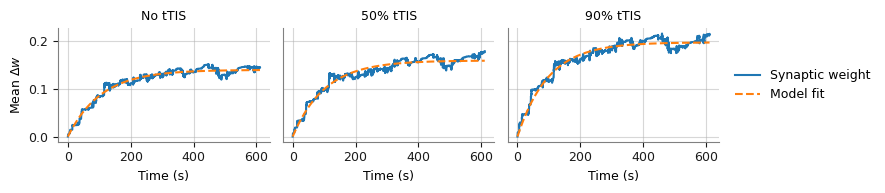

In [37]:
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize = (9, 2), sharey = True)

for ax, stimulation in zip(axs, mean_weights.keys()):
  means = mean_weights[stimulation]

  # fit model
  y_fit, results = fit_exponential(means["Mean"], means["Time"])

  t = np.array(means["Time"])
  t_shifted = t - t.min()

  # data
  ax.plot(t, means["Mean"], label = "Synaptic weight")

  # model
  ax.plot(t, y_fit, linestyle = "--", label = "Model fit")

  ax.set_xlabel("Time (s)")
  ax.set_ylabel(rf"Mean $\Delta w$")
  ax.set_title(stimulation)

  format_ax(ax)

ax.legend(
  bbox_to_anchor = (1.02, 0.5),
  loc = "center left",
  frameon = False
)

for ax in axs[1:3]:
  ax.set_ylabel("")
  ax.tick_params(left = None, labelleft = None)

plt.tight_layout()
plt.show()

In [36]:
table = fit.to_latex(index=False, float_format="%.2f", caption = "Table caption", label = "supplementary", position = "H")
print(table)

\begin{table}[H]
\caption{Table caption}
\label{supplementary}
\begin{tabular}{lrr}
\toprule
Stimulation & A & Tau \\
\midrule
No tTIS & 0.14 & 105.63 \\
50% tTIS & 0.16 & 102.59 \\
90% tTIS & 0.20 & 98.27 \\
\bottomrule
\end{tabular}
\end{table}

